# Phase 2 — Exploratory data analysis

This notebook builds the required aggregate targets and then separates the final 24 timestamps before calculating any EDA summaries. All diagnostics, statistics, charts, and segment comparisons below use the training partition only. The holdout partition is not inspected or used in EDA.

Run this notebook from the repository root with the project virtual environment active. The input files are expected in `challenge_data/`.

In [7]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd

ROOT = next(
    (candidate for candidate in [Path.cwd(), *Path.cwd().parents]
     if (candidate / "src" / "cwfc").is_dir()),
    None,
)
if ROOT is None:
    raise FileNotFoundError("Could not find the repository root containing src/cwfc")
sys.path.insert(0, str(ROOT / "src"))

from cwfc.data import load_data
from cwfc.targets import build_targets, split_train_holdout

DATA_DIR = ROOT / "challenge_data"
HOLDOUT_SIZE = 24

## Load and split

The target series is built from the VM-level readings as specified by the dataset contract. We split chronologically immediately afterward. The underscored holdout object is intentionally not used below; every EDA calculation references `train_targets` or `train_readings`.

In [8]:
readings, metadata = load_data(DATA_DIR)
all_targets = build_targets(readings)
train_targets, _holdout_targets = split_train_holdout(
    all_targets, holdout=HOLDOUT_SIZE
)

training_timestamps = set(train_targets["timestamp"])
numeric_timestamps = pd.to_numeric(readings["timestamp"], errors="coerce")
train_readings = readings.loc[numeric_timestamps.isin(training_timestamps)].copy()
train_readings["timestamp"] = pd.to_numeric(train_readings["timestamp"], errors="coerce")
train_readings["avg_cpu"] = pd.to_numeric(train_readings["avg_cpu"], errors="coerce")

print(f"Training target timestamps: {len(train_targets)}")
print(f"Training timestamp range (raw seconds): {train_targets['timestamp'].min()} to {train_targets['timestamp'].max()}")
print(f"Training UTC range: {train_targets['datetime'].min()} to {train_targets['datetime'].max()}")
train_targets.head()

Training target timestamps: 110
Training timestamp range (raw seconds): 0 to 32700
Training UTC range: 1970-01-01 00:00:00+00:00 to 1970-01-01 09:05:00+00:00


,timestamp,datetime,active_vm_count,aggregate_cpu_utilization
0,0,1970-01-01 00:00:00+00:00,10000,9.396898
1,300,1970-01-01 00:05:00+00:00,10000,9.353775
2,600,1970-01-01 00:10:00+00:00,10000,9.454383
3,900,1970-01-01 00:15:00+00:00,10000,9.224419
4,1200,1970-01-01 00:20:00+00:00,10000,9.143503


## Data quality and cadence

These checks operate on VM readings whose timestamps belong to the training partition. Repeated VM/timestamp pairs are counted explicitly; CPU readings outside the documented 0–100 percent range are also checked.

In [9]:
ordered_timestamps = train_targets["timestamp"].sort_values().drop_duplicates()
cadence_seconds = ordered_timestamps.diff().dropna()
typical_interval = cadence_seconds.median()
gap_count = int((cadence_seconds > typical_interval).sum())
duplicate_timestamp_count = int(train_targets["timestamp"].duplicated().sum())
quality = pd.Series(
    {
        "training target timestamps": len(train_targets),
        "training VM-level readings": len(train_readings),
        "unique VMs in training readings": train_readings["vm_id"].nunique(),
        "missing timestamp values": train_readings["timestamp"].isna().sum(),
        "missing VM IDs": train_readings["vm_id"].isna().sum(),
        "missing avg_cpu readings": train_readings["avg_cpu"].isna().sum(),
        "duplicate VM/timestamp pairs": train_readings.duplicated(["timestamp", "vm_id"]).sum(),
        "avg_cpu values outside [0, 100]": (
            train_readings["avg_cpu"].notna()
            & ~train_readings["avg_cpu"].between(0, 100)
        ).sum(),
    },
    name="count",
)
display(quality.to_frame())
print(f"Cadence: {typical_interval:g} seconds")
print("So what: Data is collected every 5 minutes and appears suitable for fixed-interval forecasting.")
print(f"Number of gaps: {gap_count}")
print("So what: No training intervals exceed the typical cadence, so no timestamp gaps were detected.")
print(f"Number of duplicate timestamps: {duplicate_timestamp_count}")
print("So what: Each aggregated training timestamp is unique.")
print("Observed training cadence(s), in seconds:", sorted(cadence_seconds.unique()))
print("Training timestamps sorted:", train_targets["timestamp"].is_monotonic_increasing)

,count
training target timestamps,110
training VM-level readings,1100000
unique VMs in training readings,10000
missing timestamp values,0
missing VM IDs,0
missing avg_cpu readings,0
duplicate VM/timestamp pairs,0
"avg_cpu values outside [0, 100]",0


Cadence: 300 seconds
So what: Data is collected every 5 minutes and appears suitable for fixed-interval forecasting.
Number of gaps: 0
So what: No training intervals exceed the typical cadence, so no timestamp gaps were detected.
Number of duplicate timestamps: 0
So what: Each aggregated training timestamp is unique.
Observed training cadence(s), in seconds: [300.0]
Training timestamps sorted: True


## Target and VM-level CPU distributions

Target statistics summarize only the training timestamps. VM-level CPU readings provide context for how much individual workloads vary relative to the aggregate mean.

,count,mean,std,min,25%,50%,75%,max
active_vm_count,110.0,10000.000000,0.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
aggregate_cpu_utilization,110.0,9.414089,0.193568,9.111634,9.288952,9.378121,9.507673,9.912175


,VM avg_cpu (%)
count,1.100000e+06
mean,9.414089e+00
std,1.427521e+01
min,7.158922e-03
25%,2.486945e+00
50%,5.119809e+00
75%,9.647974e+00
95%,3.729325e+01
max,9.948803e+01


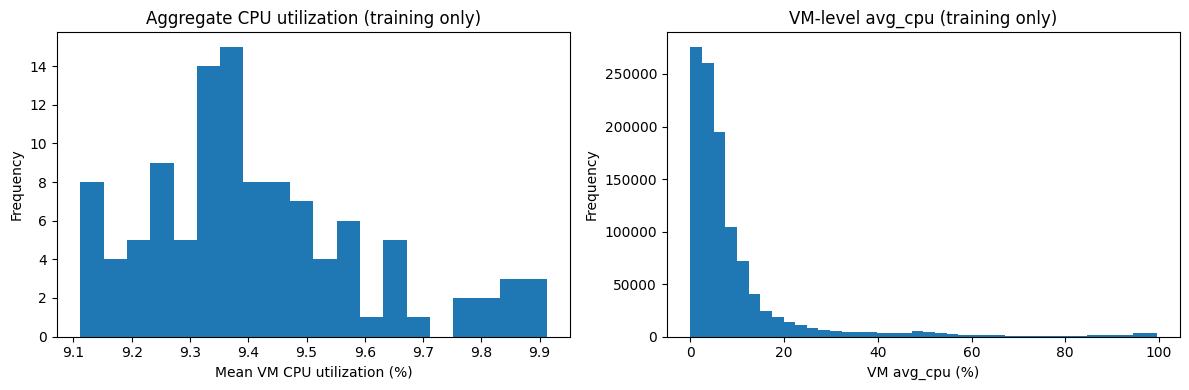

In [10]:
target_summary = train_targets[
    ["active_vm_count", "aggregate_cpu_utilization"]
].describe().T
vm_cpu_summary = train_readings["avg_cpu"].describe(
    percentiles=[0.25, 0.50, 0.75, 0.95]
)
display(target_summary)
display(vm_cpu_summary.to_frame(name="VM avg_cpu (%)"))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
train_targets["aggregate_cpu_utilization"].plot.hist(
    bins=20, ax=axes[0], title="Aggregate CPU utilization (training only)"
)
axes[0].set_xlabel("Mean VM CPU utilization (%)")
train_readings["avg_cpu"].plot.hist(
    bins=40, ax=axes[1], title="VM-level avg_cpu (training only)"
)
axes[1].set_xlabel("VM avg_cpu (%)")
plt.tight_layout()
plt.show()

## Training-period trends and peaks

The timeline retains the raw integer `timestamp` and uses the separate UTC `datetime` column for plotting. This trace covers only a short continuous window, so visible fluctuations should not be interpreted as daily or weekly seasonality.

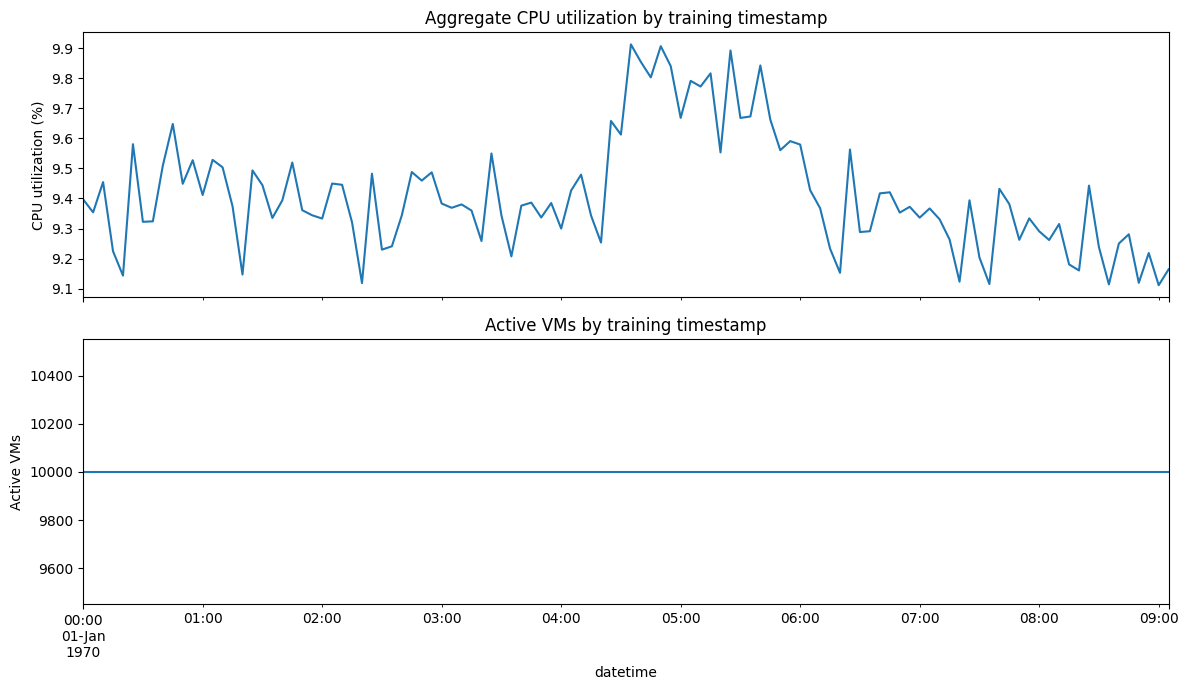

Highest aggregate CPU timestamps (training only):


,timestamp,datetime,active_vm_count,aggregate_cpu_utilization
55,16500,1970-01-01 04:35:00+00:00,10000,9.912175
58,17400,1970-01-01 04:50:00+00:00,10000,9.906192
65,19500,1970-01-01 05:25:00+00:00,10000,9.891946
56,16800,1970-01-01 04:40:00+00:00,10000,9.853998
68,20400,1970-01-01 05:40:00+00:00,10000,9.842210


Lowest aggregate CPU timestamps (training only):


,timestamp,datetime,active_vm_count,aggregate_cpu_utilization
108,32400,1970-01-01 09:00:00+00:00,10000,9.111634
103,30900,1970-01-01 08:35:00+00:00,10000,9.114320
91,27300,1970-01-01 07:35:00+00:00,10000,9.115401
28,8400,1970-01-01 02:20:00+00:00,10000,9.118488
106,31800,1970-01-01 08:50:00+00:00,10000,9.119565


In [11]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
train_targets.plot(
    x="datetime", y="aggregate_cpu_utilization", ax=axes[0],
    title="Aggregate CPU utilization by training timestamp", legend=False,
)
axes[0].set_ylabel("CPU utilization (%)")
train_targets.plot(
    x="datetime", y="active_vm_count", ax=axes[1],
    title="Active VMs by training timestamp", legend=False,
)
axes[1].set_ylabel("Active VMs")
plt.tight_layout()
plt.show()

print("Highest aggregate CPU timestamps (training only):")
display(train_targets.nlargest(5, "aggregate_cpu_utilization"))
print("Lowest aggregate CPU timestamps (training only):")
display(train_targets.nsmallest(5, "aggregate_cpu_utilization"))

### Aggregate CPU with a trailing rolling mean

The 12-observation window corresponds to one hour at five-minute cadence. It smooths short-term noise while using only current and prior training observations. The x-axis uses the separate UTC datetime column; raw timestamps remain available in `train_targets`.

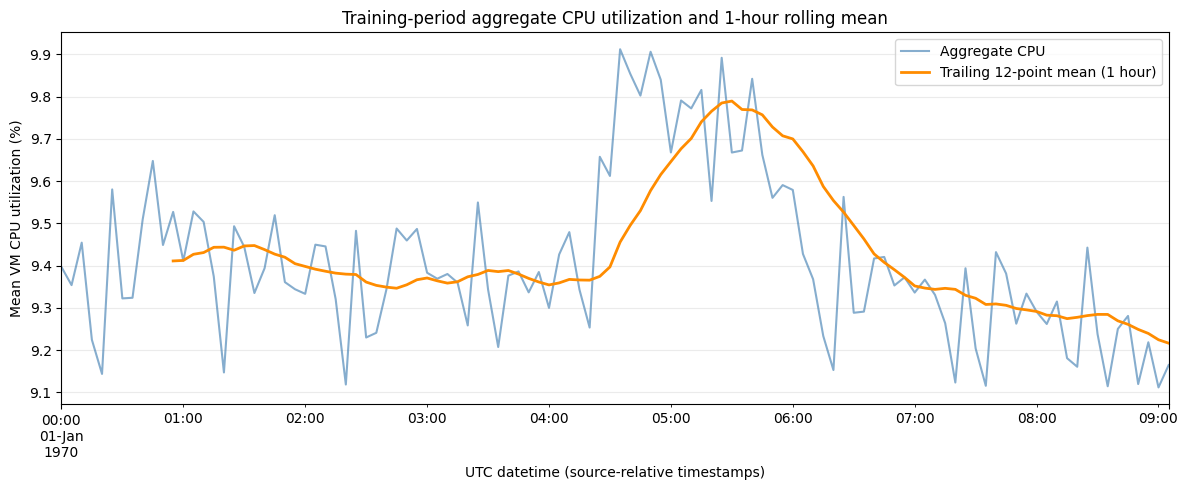

Training aggregate CPU mean: 9.414%
Training aggregate CPU standard deviation: 0.194 percentage points
Trailing rolling mean, first available: 9.411%
Trailing rolling mean, last training timestamp: 9.216%
Highest single-timestamp aggregate CPU: 9.912% at raw timestamp 16500


In [15]:
rolling_window = 12
cpu_series = train_targets.set_index("datetime")["aggregate_cpu_utilization"]
cpu_rolling_mean = cpu_series.rolling(rolling_window, min_periods=rolling_window).mean()

fig, ax = plt.subplots(figsize=(12, 5))
cpu_series.plot(ax=ax, color="steelblue", alpha=0.65, label="Aggregate CPU")
cpu_rolling_mean.plot(ax=ax, color="darkorange", linewidth=2, label="Trailing 12-point mean (1 hour)")
ax.set_title("Training-period aggregate CPU utilization and 1-hour rolling mean")
ax.set_xlabel("UTC datetime (source-relative timestamps)")
ax.set_ylabel("Mean VM CPU utilization (%)")
ax.legend()
ax.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()

print(f"Training aggregate CPU mean: {cpu_series.mean():.3f}%")
print(f"Training aggregate CPU standard deviation: {cpu_series.std():.3f} percentage points")
print(f"Trailing rolling mean, first available: {cpu_rolling_mean.dropna().iloc[0]:.3f}%")
print(f"Trailing rolling mean, last training timestamp: {cpu_rolling_mean.iloc[-1]:.3f}%")
peak_row = train_targets.loc[train_targets["aggregate_cpu_utilization"].idxmax()]
print(f"Highest single-timestamp aggregate CPU: {peak_row['aggregate_cpu_utilization']:.3f}% at raw timestamp {int(peak_row['timestamp'])}")

## VM lifetimes and churn

Lifetimes are calculated from each VM's first and last appearances in the training readings only. The training-window endpoints are censored: VMs already present at the first timestamp may have arrived earlier, and VMs still present at the final timestamp may continue afterward. Therefore, arrivals/departures at those boundaries are excluded from internal churn counts.

In [13]:
vm_appearances = (
    train_readings.dropna(subset=["timestamp", "vm_id"])
    .drop_duplicates(["timestamp", "vm_id"])
    .groupby("vm_id")["timestamp"]
    .agg(first_appearance="min", last_appearance="max")
)
vm_appearances["lifetime_seconds"] = (
    vm_appearances["last_appearance"] - vm_appearances["first_appearance"]
)

internal_timestamps = set(train_targets["timestamp"].iloc[1:-1])
arrivals_by_timestamp = vm_appearances.groupby("first_appearance").size()
departures_by_timestamp = vm_appearances.groupby("last_appearance").size()
internal_arrivals = int(
    arrivals_by_timestamp.reindex(internal_timestamps, fill_value=0).sum()
)
internal_departures = int(
    departures_by_timestamp.reindex(internal_timestamps, fill_value=0).sum()
)

lifetime_summary = pd.Series(
    {
        "Median observed VM lifetime (seconds)": vm_appearances["lifetime_seconds"].median(),
        "Mean observed VM lifetime (seconds)": vm_appearances["lifetime_seconds"].mean(),
        "Median observed VM lifetime (hours)": vm_appearances["lifetime_seconds"].median() / 3600,
        "Mean observed VM lifetime (hours)": vm_appearances["lifetime_seconds"].mean() / 3600,
    },
    name="value",
)
display(lifetime_summary.to_frame())

print(f"VM arrivals within the observed training window: {internal_arrivals}")
print("So what: No VMs first appear after the left-censored start of the training window.")
print(f"VM departures within the observed training window: {internal_departures}")
print("So what: No VMs disappear before the right-censored end of the training window.")
print(
    "Boundary note: "
    f"{int(arrivals_by_timestamp.get(train_targets['timestamp'].iloc[0], 0))} VMs are first seen at the start and "
    f"{int(departures_by_timestamp.get(train_targets['timestamp'].iloc[-1], 0))} are last seen at the end; "
    "these are not counted as proven arrivals/departures."
)

,value
Median observed VM lifetime (seconds),32700.000000
Mean observed VM lifetime (seconds),32700.000000
Median observed VM lifetime (hours),9.083333
Mean observed VM lifetime (hours),9.083333


VM arrivals within the observed training window: 0
So what: No VMs first appear after the left-censored start of the training window.
VM departures within the observed training window: 0
So what: No VMs disappear before the right-censored end of the training window.
Boundary note: 10000 VMs are first seen at the start and 10000 are last seen at the end; these are not counted as proven arrivals/departures.


## Per-VM CPU utilization

For each VM, calculate mean `avg_cpu` across its training-period readings only. The thresholds show how common very low and high sustained average utilization is; individual spikes are not classified as high mean CPU.

In [14]:
per_vm_mean_cpu = (
    train_readings.dropna(subset=["vm_id", "avg_cpu"])
    .groupby("vm_id")["avg_cpu"]
    .mean()
)
vm_count = len(per_vm_mean_cpu)
low_cpu_count = int((per_vm_mean_cpu < 5).sum())
high_cpu_count = int((per_vm_mean_cpu > 50).sum())
low_cpu_share = 100 * low_cpu_count / vm_count if vm_count else float("nan")
high_cpu_share = 100 * high_cpu_count / vm_count if vm_count else float("nan")

print(f"VMs with mean CPU <5%: {low_cpu_count} ({low_cpu_share:.2f}%)")
print("So what: Nearly half of VMs average below 5% CPU, suggesting substantial low-utilization capacity in this trace.")
print(f"VMs with mean CPU >50%: {high_cpu_count} ({high_cpu_share:.2f}%)")
print("So what: Only a small share of VMs sustain mean CPU above 50%; this does not rule out short-lived spikes.")

VMs with mean CPU <5%: 4635 (46.35%)
So what: Nearly half of VMs average below 5% CPU, suggesting substantial low-utilization capacity in this trace.
VMs with mean CPU >50%: 220 (2.20%)
So what: Only a small share of VMs sustain mean CPU above 50%; this does not rule out short-lived spikes.


## Workload segments

VM category, virtual-core bucket, and memory bucket are descriptive segments only. CPU-summary columns from metadata are deliberately excluded; the CPU values in these summaries come from training-period VM-level readings.

Training-only breakdown by vm_category


,reading_count,vm_count,mean_vm_cpu,median_vm_cpu
vm_category,,,,
Delay-insensitive,679800,6180,8.257266,5.160160
Interactive,340010,3091,11.505150,5.295715
Unknown,80190,729,10.354689,3.415575


Training-only breakdown by virtual_core_bucket


,reading_count,vm_count,mean_vm_cpu,median_vm_cpu
virtual_core_bucket,,,,
2,828740,7534,9.764163,5.520978
4,209880,1908,7.918723,2.900452
8,53460,486,9.658399,4.334916
24,6820,62,11.428831,6.825058
>24,1100,10,6.619469,2.610547


Training-only breakdown by memory_gb_bucket


,reading_count,vm_count,mean_vm_cpu,median_vm_cpu
memory_gb_bucket,,,,
2,429440,3904,8.802254,6.685325
4,272250,2475,11.459541,4.433399
8,236060,2146,9.143401,2.850382
32,152130,1383,7.814017,2.677349
64,9020,82,11.217160,4.348273
>64,1100,10,6.619469,2.610547


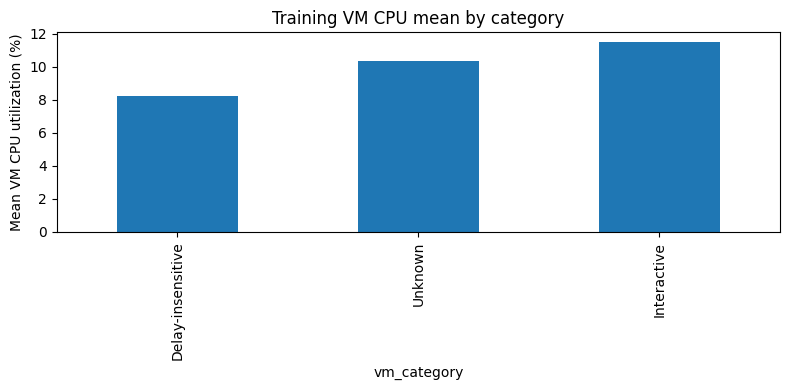

In [12]:
segment_columns = [
    column
    for column in ["vm_id", "vm_category", "virtual_core_bucket", "memory_gb_bucket"]
    if column in metadata.columns
]
segment_metadata = metadata[segment_columns].drop_duplicates("vm_id")
segmented_readings = train_readings.merge(
    segment_metadata, on="vm_id", how="left", validate="many_to_one"
)

for segment in ["vm_category", "virtual_core_bucket", "memory_gb_bucket"]:
    if segment in segmented_readings.columns:
        summary = (
            segmented_readings.groupby(segment, dropna=False)
            .agg(
                reading_count=("avg_cpu", "count"),
                vm_count=("vm_id", "nunique"),
                mean_vm_cpu=("avg_cpu", "mean"),
                median_vm_cpu=("avg_cpu", "median"),
            )
            .sort_values("reading_count", ascending=False)
        )
        print(f"Training-only breakdown by {segment}")
        display(summary)

if "vm_category" in segmented_readings.columns:
    category_means = segmented_readings.groupby("vm_category")["avg_cpu"].mean().sort_values()
    category_means.plot.bar(figsize=(8, 4), title="Training VM CPU mean by category")
    plt.ylabel("Mean VM CPU utilization (%)")
    plt.tight_layout()
    plt.show()

## Interpretation and limitations

See [`notes.md`](../notes.md) for the training-only findings and operational interpretation. This public trace spans only about 11 hours, so it cannot establish daily/weekly seasonality. Any model selection must still use rolling-origin validation entirely inside the training partition; this notebook does not inspect the holdout labels or select a model.